# Notebook 06 — Model Interpretation and XGBoost SHAP

Option C architecture: model-specific native interpretation for all five models and detailed SHAP for XGBoost only. Raw importance magnitudes are never compared across methods.


## 1. Imports and interpretation configuration


In [14]:
from __future__ import annotations

import sys
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import shap
import xgboost as xgb
from IPython.display import display
from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
RANDOM_STATE = 42
TOP_N_FEATURES = 15
SHAP_SAMPLE_SIZE = 500
FIGURE_DPI = 300
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = FIGURE_DPI


## 2. Paths and helpers


In [15]:
def find_source_root(start_path: Path) -> Path:
    current = start_path.resolve()
    for candidate in [current, *current.parents]:
        if candidate.name == "Source":
            return candidate
        nested = candidate / "Source"
        if nested.exists() and nested.is_dir():
            return nested.resolve()
    raise FileNotFoundError("Could not locate Source.")


CURRENT_WORKING_DIRECTORY = Path.cwd().resolve()
SOURCE_ROOT = find_source_root(CURRENT_WORKING_DIRECTORY)
REPO_ROOT = SOURCE_ROOT.parent
if str(REPO_ROOT) not in sys.path:
    sys.path.insert(0, str(REPO_ROOT))

from Source.src.path import DATA_REPORTS_DIR, FIGURES_DIR
from Source.src.utils.feature_display import build_feature_mapping_table, get_feature_display_name

DATA_REPORTS_DIR = Path(DATA_REPORTS_DIR)
FIGURES_DIR = Path(FIGURES_DIR)
if not DATA_REPORTS_DIR.exists() or not FIGURES_DIR.exists():
    raise FileNotFoundError("Required report folders are missing.")


def load_required_csv(filename: str) -> pd.DataFrame:
    path = DATA_REPORTS_DIR / filename
    if not path.exists():
        raise FileNotFoundError(f"Missing interpretation input: {path}")
    frame = pd.read_csv(path)
    if frame.empty:
        raise ValueError(f"Interpretation input is empty: {path}")
    print(f"Loaded {filename}: shape={frame.shape}")
    return frame


def save_table(df: pd.DataFrame, filename: str, title: str) -> Path:
    path = DATA_REPORTS_DIR / filename
    df.to_csv(path, index=False)
    print(f"{title}: shape={df.shape}; saved={path}")
    display(df)
    return path


def save_figure(filename: str, tight: bool = True) -> Path:
    path = FIGURES_DIR / filename
    if tight:
        try:
            plt.tight_layout()
        except Exception:
            pass
    plt.savefig(path, dpi=300, bbox_inches="tight")
    print(f"Saved 300-DPI figure: {path}")
    display(plt.gcf())
    plt.close()
    return path


def standardize_driver_group(row: pd.Series) -> str:
    feature_code = str(row.get("Feature_Code", ""))
    base_feature = str(row.get("Base_Feature", feature_code))
    if feature_code == "Tenure" or base_feature == "Tenure": return "Tenure"
    if feature_code == "tenure_group" or base_feature == "tenure_group": return "Tenure"
    if feature_code == "Contract" or base_feature == "Contract": return "Contract type"
    text = " ".join(str(row.get(column, "")) for column in ["Feature_Code", "Feature_Display_Name", "Base_Feature", "Feature_Group"]).lower()
    if "contract" in text: return "Contract type"
    if "tenure" in text: return "Tenure"
    if "internet" in text: return "Internet service"
    if "tech support" in text or "online security" in text or "security" in text: return "Tech support / online security"
    if "monthly" in text or "total charges" in text or "charge" in text: return "Monthly charges / total charges"
    if "payment" in text: return "Payment method"
    if "service diversity" in text: return "Service diversity"
    if "paperless" in text: return "Paperless billing"
    return "Other customer or service profile"


def plot_horizontal_bar(df: pd.DataFrame, value_col: str, title: str, xlabel: str, filename: str, color: str) -> Path:
    plot_df = df.head(TOP_N_FEATURES).iloc[::-1]
    fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.45)))
    ax.barh(plot_df["Feature_Display_Name"], plot_df[value_col], color=color)
    ax.set_title(title)
    ax.set_xlabel(xlabel)
    ax.set_ylabel("")
    ax.grid(axis="x", alpha=0.25)
    return save_figure(filename)


def prepare_native_importance(df: pd.DataFrame, method: str, unit: str) -> pd.DataFrame:
    work = df.copy().sort_values("Importance", ascending=False).reset_index(drop=True)
    work["Feature_Display_Name"] = work["Feature_Code"].map(get_feature_display_name)
    work["Rank"] = np.arange(1, len(work) + 1)
    work["Method"] = method
    work["Value_Unit"] = unit
    work["Driver_Group"] = work.apply(standardize_driver_group, axis=1)
    work["Comparison_Note"] = "Method-specific magnitude; compare ranks, not raw values across methods."
    return work[["Feature_Code", "Feature_Display_Name", "Importance", "Rank", "Method", "Value_Unit", "Driver_Group", "Comparison_Note"]]


## 3. Load model-specific interpretation inputs


In [16]:
logistic_coefficients = load_required_csv("logistic_coefficients.csv")
random_forest_importance = load_required_csv("random_forest_feature_importance.csv")
xgboost_importance = load_required_csv("xgboost_feature_importance.csv")
lightgbm_importance = load_required_csv("lightgbm_feature_importance.csv")
catboost_importance = load_required_csv("catboost_feature_importance.csv")
feature_mapping_xgboost = load_required_csv("feature_name_mapping_xgboost.csv")


Loaded logistic_coefficients.csv: shape=(26, 16)
Loaded random_forest_feature_importance.csv: shape=(18, 10)
Loaded xgboost_feature_importance.csv: shape=(18, 14)
Loaded lightgbm_feature_importance.csv: shape=(18, 13)
Loaded catboost_feature_importance.csv: shape=(18, 13)
Loaded feature_name_mapping_xgboost.csv: shape=(18, 9)


## 4. Logistic Regression coefficients


Logistic coefficient interpretation: shape=(26, 10); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_logistic_coefficients_summary.csv


,Feature_Code,Feature_Display_Name,Coefficient,Abs_Coefficient,Direction,Rank,Method,Value_Unit,Driver_Group,Comparison_Note
0,TotalCharges,Total Charges,-0.766378,0.766378,decreases churn probability,1,Logistic Regression coefficients,coefficient on the logistic model scale,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
1,Contract_24,Contract Type = Two year,-0.683150,0.683150,decreases churn probability,2,Logistic Regression coefficients,coefficient on the logistic model scale,Contract type,"Method-specific magnitude; compare ranks, not ..."
2,Dependents_Yes,Dependents = Yes,-0.649922,0.649922,decreases churn probability,3,Logistic Regression coefficients,coefficient on the logistic model scale,Other customer or service profile,"Method-specific magnitude; compare ranks, not ..."
3,InternetService_No,Internet Service = No Internet Service,-0.378273,0.378273,decreases churn probability,4,Logistic Regression coefficients,coefficient on the logistic model scale,Internet service,"Method-specific magnitude; compare ranks, not ..."
4,Contract_12,Contract Type = One year,-0.336179,0.336179,decreases churn probability,5,Logistic Regression coefficients,coefficient on the logistic model scale,Contract type,"Method-specific magnitude; compare ranks, not ..."
5,MonthlyCharges,Monthly Charges,0.334798,0.334798,increases churn probability,6,Logistic Regression coefficients,coefficient on the logistic model scale,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
6,monthly_charges_ratio,Monthly Charges Ratio,0.334798,0.334798,increases churn probability,7,Logistic Regression coefficients,coefficient on the logistic model scale,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
7,PaperlessBilling_1,Paperless Billing = Yes,0.236857,0.236857,increases churn probability,8,Logistic Regression coefficients,coefficient on the logistic model scale,Paperless billing,"Method-specific magnitude; compare ranks, not ..."
8,Tenure,Tenure (Months),-0.208399,0.208399,decreases churn probability,9,Logistic Regression coefficients,coefficient on the logistic model scale,Tenure,"Method-specific magnitude; compare ranks, not ..."
9,InternetService_Fiber optic,Internet Service = Fiber optic,0.159882,0.159882,increases churn probability,10,Logistic Regression coefficients,coefficient on the logistic model scale,Internet service,"Method-specific magnitude; compare ranks, not ..."


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_01_logistic_top_coefficients.png


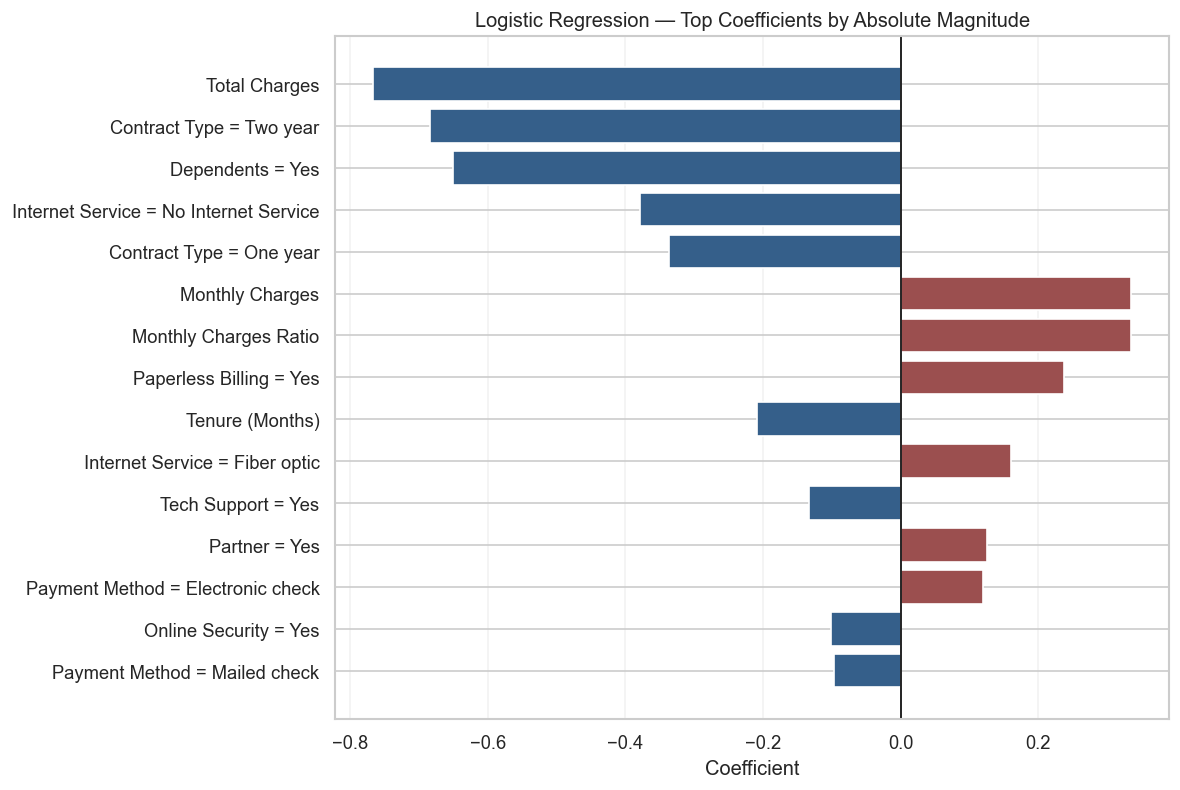

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_interpretation_01_logistic_top_coefficients.png')

In [17]:
logistic_summary = logistic_coefficients.copy()
logistic_summary["Feature_Display_Name"] = logistic_summary["Feature_Code"].map(get_feature_display_name)
if "Abs_Coefficient" not in logistic_summary:
    logistic_summary["Abs_Coefficient"] = logistic_summary["Coefficient"].abs()
if "Direction" not in logistic_summary:
    logistic_summary["Direction"] = np.where(logistic_summary["Coefficient"] >= 0, "Positive", "Negative")
logistic_summary = logistic_summary.sort_values("Abs_Coefficient", ascending=False).reset_index(drop=True)
logistic_summary["Rank"] = np.arange(1, len(logistic_summary) + 1)
logistic_summary["Method"] = "Logistic Regression coefficients"
logistic_summary["Value_Unit"] = "coefficient on the logistic model scale"
logistic_summary["Driver_Group"] = logistic_summary.apply(standardize_driver_group, axis=1)
logistic_summary["Comparison_Note"] = "Method-specific magnitude; compare ranks, not raw values across methods."
logistic_output_columns = ["Feature_Code", "Feature_Display_Name", "Coefficient", "Abs_Coefficient", "Direction", "Rank", "Method", "Value_Unit", "Driver_Group", "Comparison_Note"]
logistic_coefficients_summary = logistic_summary[logistic_output_columns]
save_table(logistic_coefficients_summary, "model_interpretation_logistic_coefficients_summary.csv", "Logistic coefficient interpretation")

plot_df = logistic_coefficients_summary.head(TOP_N_FEATURES).iloc[::-1]
colors = np.where(plot_df["Coefficient"] >= 0, "#9b4f4f", "#355f8a")
fig, ax = plt.subplots(figsize=(10, max(6, len(plot_df) * 0.45)))
ax.barh(plot_df["Feature_Display_Name"], plot_df["Coefficient"], color=colors)
ax.axvline(0, color="black", linewidth=1)
ax.set_title("Logistic Regression — Top Coefficients by Absolute Magnitude")
ax.set_xlabel("Coefficient")
ax.set_ylabel("")
ax.grid(axis="x", alpha=0.25)
save_figure("model_interpretation_01_logistic_top_coefficients.png")


## 5. Native feature importance for four tree models


Random Forest native importance: shape=(15, 8); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_random_forest_top_features.csv


,Feature_Code,Feature_Display_Name,Importance,Rank,Method,Value_Unit,Driver_Group,Comparison_Note
0,TotalCharges,Total Charges,0.139764,1,Random Forest impurity importance,impurity importance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
1,monthly_charges_ratio,Monthly Charges Ratio,0.136337,2,Random Forest impurity importance,impurity importance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
2,MonthlyCharges,Monthly Charges,0.135226,3,Random Forest impurity importance,impurity importance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
3,Tenure,Tenure (Months),0.124372,4,Random Forest impurity importance,impurity importance,Tenure,"Method-specific magnitude; compare ranks, not ..."
4,Contract,Contract Type,0.121987,5,Random Forest impurity importance,impurity importance,Contract type,"Method-specific magnitude; compare ranks, not ..."
5,tenure_group,Tenure Group,0.053841,6,Random Forest impurity importance,impurity importance,Tenure,"Method-specific magnitude; compare ranks, not ..."
6,Dependents,Dependents,0.049052,7,Random Forest impurity importance,impurity importance,Other customer or service profile,"Method-specific magnitude; compare ranks, not ..."
7,PaymentMethod,Payment Method,0.040458,8,Random Forest impurity importance,impurity importance,Payment method,"Method-specific magnitude; compare ranks, not ..."
8,InternetService,Internet Service,0.038583,9,Random Forest impurity importance,impurity importance,Internet service,"Method-specific magnitude; compare ranks, not ..."
9,service_diversity,Service Diversity Score,0.034653,10,Random Forest impurity importance,impurity importance,Service diversity,"Method-specific magnitude; compare ranks, not ..."


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_02_random_forest_top_importance.png


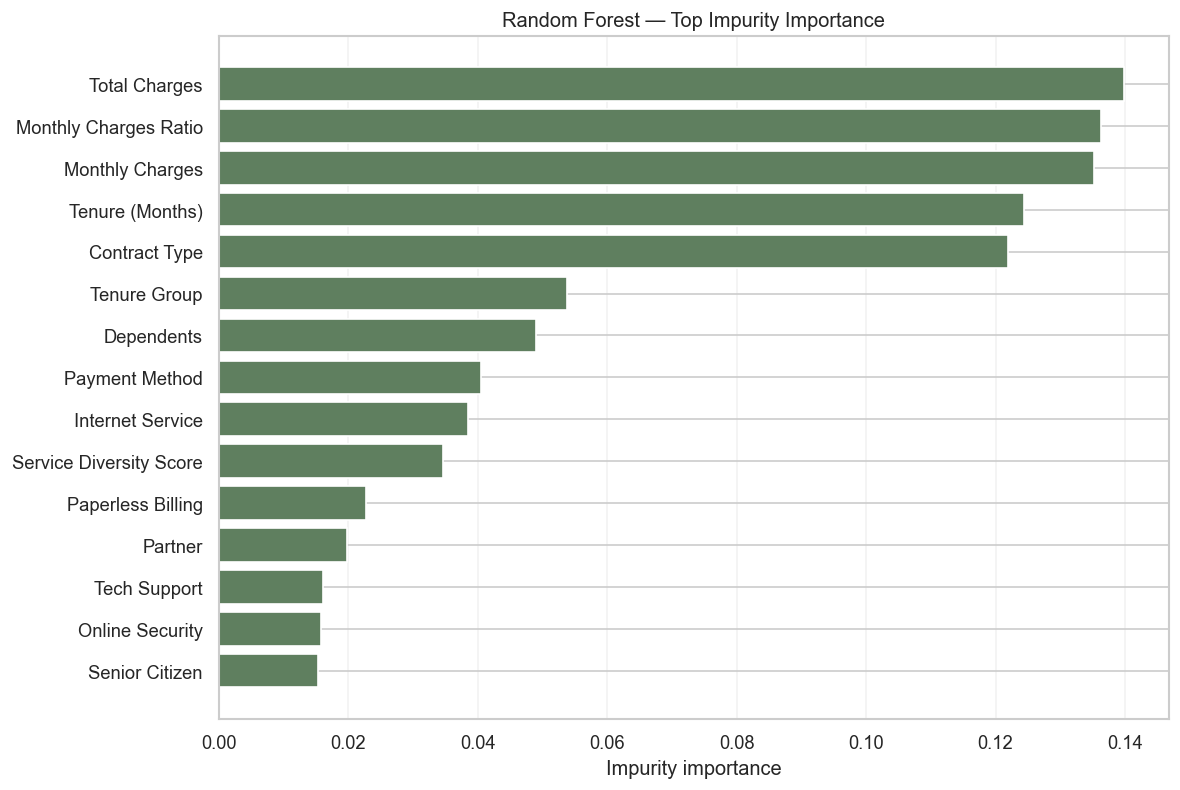

XGBoost gain importance: shape=(15, 8); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_xgboost_top_features.csv


,Feature_Code,Feature_Display_Name,Importance,Rank,Method,Value_Unit,Driver_Group,Comparison_Note
0,Contract,Contract Type,106.530678,1,XGBoost gain importance,mean gain,Contract type,"Method-specific magnitude; compare ranks, not ..."
1,Dependents,Dependents,31.765200,2,XGBoost gain importance,mean gain,Other customer or service profile,"Method-specific magnitude; compare ranks, not ..."
2,InternetService,Internet Service,25.567146,3,XGBoost gain importance,mean gain,Internet service,"Method-specific magnitude; compare ranks, not ..."
3,tenure_group,Tenure Group,13.311166,4,XGBoost gain importance,mean gain,Tenure,"Method-specific magnitude; compare ranks, not ..."
4,Tenure,Tenure (Months),10.931134,5,XGBoost gain importance,mean gain,Tenure,"Method-specific magnitude; compare ranks, not ..."
5,PaperlessBilling,Paperless Billing,9.441069,6,XGBoost gain importance,mean gain,Paperless billing,"Method-specific magnitude; compare ranks, not ..."
6,TechSupport,Tech Support,9.205020,7,XGBoost gain importance,mean gain,Tech support / online security,"Method-specific magnitude; compare ranks, not ..."
7,OnlineSecurity,Online Security,7.872219,8,XGBoost gain importance,mean gain,Tech support / online security,"Method-specific magnitude; compare ranks, not ..."
8,MonthlyCharges,Monthly Charges,7.493329,9,XGBoost gain importance,mean gain,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
9,service_diversity,Service Diversity Score,7.201778,10,XGBoost gain importance,mean gain,Service diversity,"Method-specific magnitude; compare ranks, not ..."


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_03_xgboost_top_importance.png


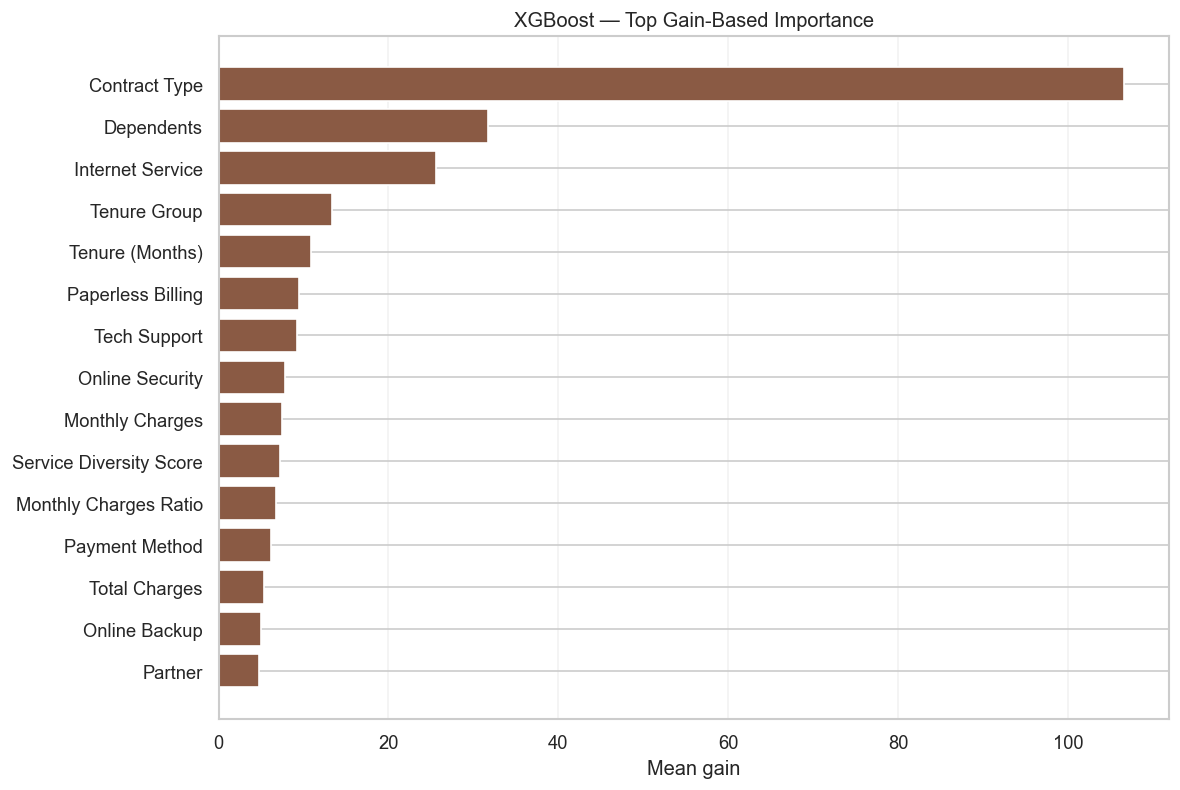

LightGBM gain importance: shape=(15, 8); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_lightgbm_top_features.csv


,Feature_Code,Feature_Display_Name,Importance,Rank,Method,Value_Unit,Driver_Group,Comparison_Note
0,Contract,Contract Type,12816.675136,1,LightGBM gain importance,gain importance,Contract type,"Method-specific magnitude; compare ranks, not ..."
1,MonthlyCharges,Monthly Charges,8762.445112,2,LightGBM gain importance,gain importance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
2,Tenure,Tenure (Months),5872.901550,3,LightGBM gain importance,gain importance,Tenure,"Method-specific magnitude; compare ranks, not ..."
3,TotalCharges,Total Charges,5797.801081,4,LightGBM gain importance,gain importance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
4,Dependents,Dependents,3182.190584,5,LightGBM gain importance,gain importance,Other customer or service profile,"Method-specific magnitude; compare ranks, not ..."
5,PaymentMethod,Payment Method,1256.018465,6,LightGBM gain importance,gain importance,Payment method,"Method-specific magnitude; compare ranks, not ..."
6,monthly_charges_ratio,Monthly Charges Ratio,1211.770971,7,LightGBM gain importance,gain importance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
7,service_diversity,Service Diversity Score,1074.781000,8,LightGBM gain importance,gain importance,Service diversity,"Method-specific magnitude; compare ranks, not ..."
8,PaperlessBilling,Paperless Billing,785.884680,9,LightGBM gain importance,gain importance,Paperless billing,"Method-specific magnitude; compare ranks, not ..."
9,Partner,Partner,714.331698,10,LightGBM gain importance,gain importance,Other customer or service profile,"Method-specific magnitude; compare ranks, not ..."


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_08_lightgbm_top_importance.png


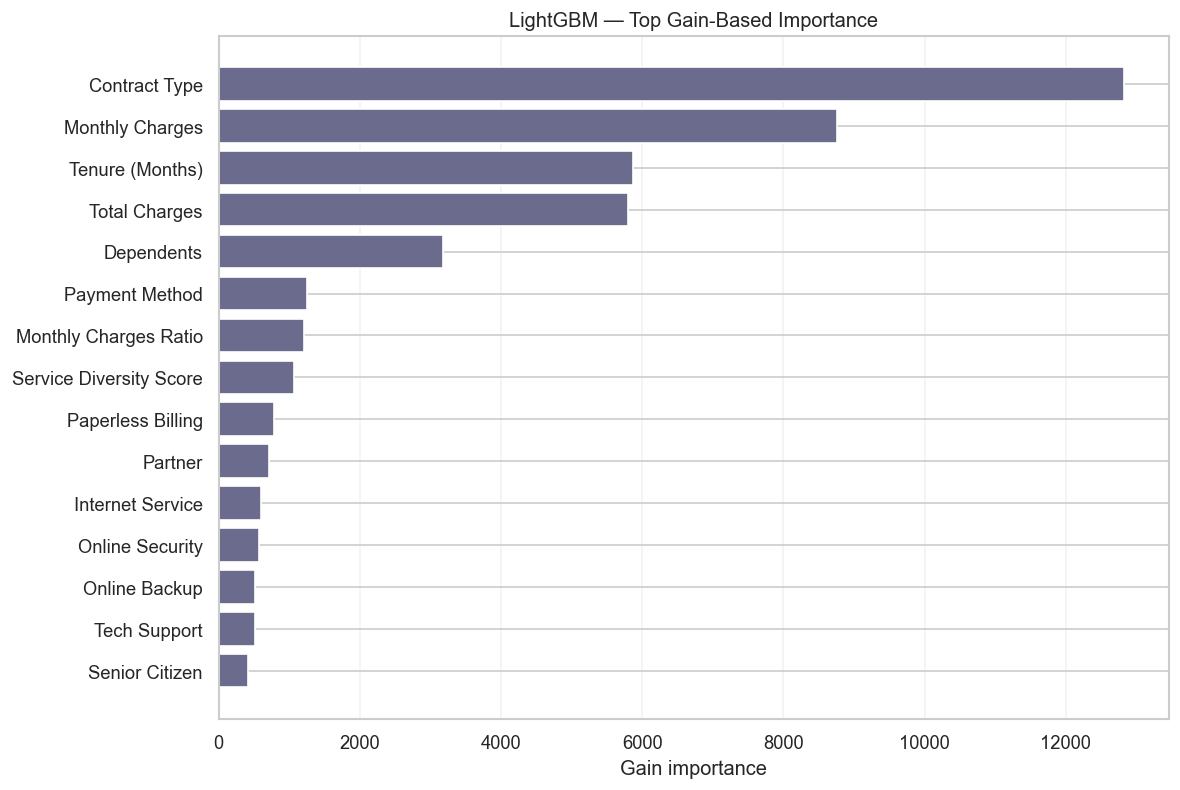

CatBoost native FeatureImportance: shape=(15, 8); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_catboost_top_features.csv


,Feature_Code,Feature_Display_Name,Importance,Rank,Method,Value_Unit,Driver_Group,Comparison_Note
0,Dependents,Dependents,15.557682,1,CatBoost FeatureImportance,CatBoost native FeatureImportance,Other customer or service profile,"Method-specific magnitude; compare ranks, not ..."
1,Contract,Contract Type,12.947577,2,CatBoost FeatureImportance,CatBoost native FeatureImportance,Contract type,"Method-specific magnitude; compare ranks, not ..."
2,TotalCharges,Total Charges,10.514952,3,CatBoost FeatureImportance,CatBoost native FeatureImportance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
3,monthly_charges_ratio,Monthly Charges Ratio,10.198390,4,CatBoost FeatureImportance,CatBoost native FeatureImportance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
4,Tenure,Tenure (Months),8.920877,5,CatBoost FeatureImportance,CatBoost native FeatureImportance,Tenure,"Method-specific magnitude; compare ranks, not ..."
5,MonthlyCharges,Monthly Charges,6.835459,6,CatBoost FeatureImportance,CatBoost native FeatureImportance,Monthly charges / total charges,"Method-specific magnitude; compare ranks, not ..."
6,PaymentMethod,Payment Method,6.330801,7,CatBoost FeatureImportance,CatBoost native FeatureImportance,Payment method,"Method-specific magnitude; compare ranks, not ..."
7,InternetService,Internet Service,5.886005,8,CatBoost FeatureImportance,CatBoost native FeatureImportance,Internet service,"Method-specific magnitude; compare ranks, not ..."
8,service_diversity,Service Diversity Score,4.593397,9,CatBoost FeatureImportance,CatBoost native FeatureImportance,Service diversity,"Method-specific magnitude; compare ranks, not ..."
9,tenure_group,Tenure Group,4.116453,10,CatBoost FeatureImportance,CatBoost native FeatureImportance,Tenure,"Method-specific magnitude; compare ranks, not ..."


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_09_catboost_top_importance.png


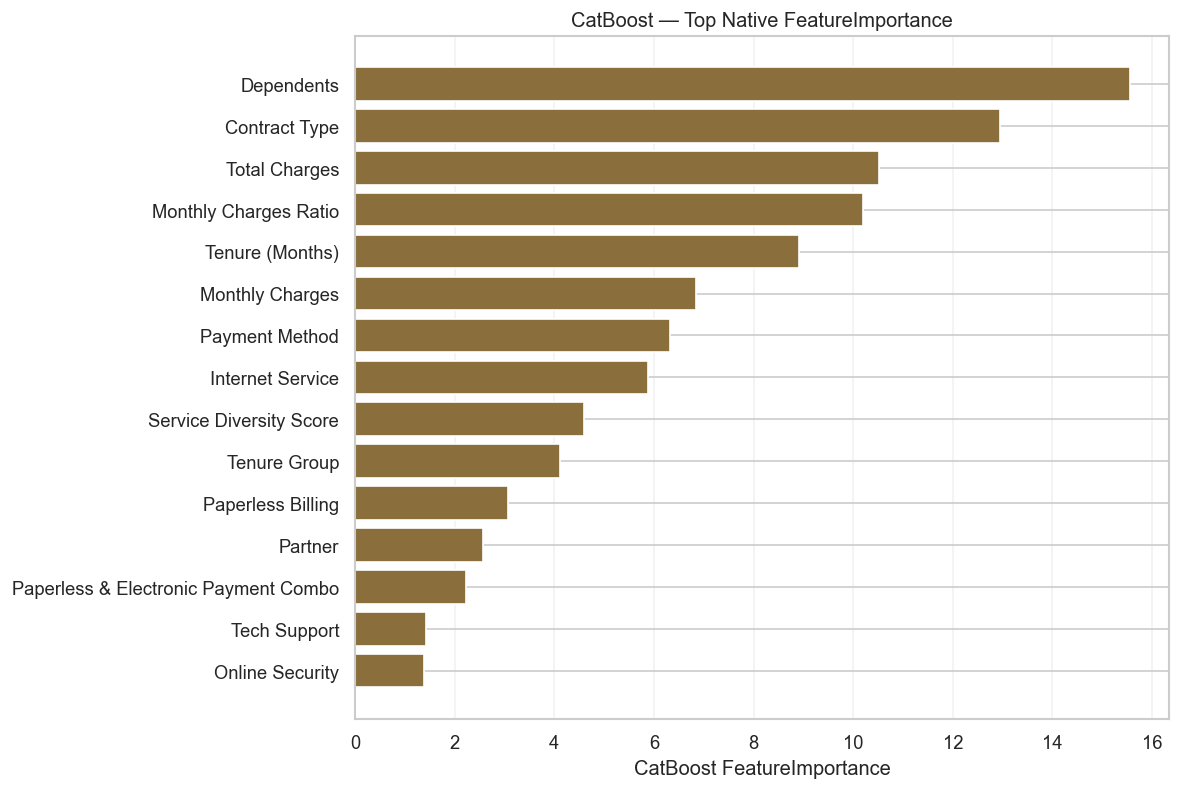

In [18]:
random_forest_top_features = prepare_native_importance(random_forest_importance, "Random Forest impurity importance", "impurity importance").head(TOP_N_FEATURES)
xgboost_top_features = prepare_native_importance(xgboost_importance, "XGBoost gain importance", "mean gain").head(TOP_N_FEATURES)
lightgbm_top_features = prepare_native_importance(lightgbm_importance, "LightGBM gain importance", "gain importance").head(TOP_N_FEATURES)
catboost_top_features = prepare_native_importance(catboost_importance, "CatBoost FeatureImportance", "CatBoost native FeatureImportance").head(TOP_N_FEATURES)

native_outputs = [
    (random_forest_top_features, "model_interpretation_random_forest_top_features.csv", "Random Forest native importance", "Random Forest — Top Impurity Importance", "Impurity importance", "model_interpretation_02_random_forest_top_importance.png", "#5f7f5f"),
    (xgboost_top_features, "model_interpretation_xgboost_top_features.csv", "XGBoost gain importance", "XGBoost — Top Gain-Based Importance", "Mean gain", "model_interpretation_03_xgboost_top_importance.png", "#8a5a44"),
    (lightgbm_top_features, "model_interpretation_lightgbm_top_features.csv", "LightGBM gain importance", "LightGBM — Top Gain-Based Importance", "Gain importance", "model_interpretation_08_lightgbm_top_importance.png", "#6b6b8d"),
    (catboost_top_features, "model_interpretation_catboost_top_features.csv", "CatBoost native FeatureImportance", "CatBoost — Top Native FeatureImportance", "CatBoost FeatureImportance", "model_interpretation_09_catboost_top_importance.png", "#8a6f3d"),
]
for table, csv_name, csv_title, figure_title, xlabel, figure_name, color in native_outputs:
    save_table(table, csv_name, csv_title)
    plot_horizontal_bar(table, "Importance", figure_title, xlabel, figure_name, color)


## 6. Recreate the Notebook 04 XGBoost specification


In [19]:
from Source.src.main import run_pipeline

result = run_pipeline(force_ingestion=False, use_database=False)
outputs = result["outputs"]
tree_train = outputs["tree"]["train"]
tree_val = outputs["tree"]["validation"]
tree_test = outputs["tree"]["test"]

X_train = tree_train.drop(columns=["ID", "Churn"])
y_train = tree_train["Churn"].astype(int)
X_val = tree_val.drop(columns=["ID", "Churn"])
y_val = tree_val["Churn"].astype(int)
X_test = tree_test.drop(columns=["ID", "Churn"])
y_test = tree_test["Churn"].astype(int)

if X_train.shape[1] != 18 or list(X_train.columns) != list(X_val.columns) or list(X_train.columns) != list(X_test.columns):
    raise ValueError("Tree-pipeline feature contract is inconsistent across splits.")
if list(X_train.columns) != feature_mapping_xgboost["Feature_Code"].tolist():
    raise ValueError("XGBoost feature mapping does not match tree-pipeline feature order.")
if not {'Tenure', 'tenure_group'}.issubset(X_train.columns):
    raise ValueError('Tenure and tenure_group must remain separate tree-model inputs.')
expected_tenure_labels = {'Tenure': 'Tenure (Months)', 'tenure_group': 'Tenure Group'}
actual_tenure_labels = feature_mapping_xgboost.set_index('Feature_Code')['Feature_Display_Name'].to_dict()
for feature_code, expected_label in expected_tenure_labels.items():
    if actual_tenure_labels.get(feature_code) != expected_label:
        raise ValueError(f'Invalid tenure mapping for {feature_code}: {actual_tenure_labels.get(feature_code)}')
if feature_mapping_xgboost['Feature_Display_Name'].duplicated().any():
    raise ValueError('Duplicate XGBoost feature display labels detected.')

negative_count = int((y_train == 0).sum())
positive_count = int((y_train == 1).sum())
scale_pos_weight = negative_count / positive_count
EXPECTED_XGB_PARAMS = {
    "n_estimators": 300, "max_depth": 4, "learning_rate": 0.05,
    "subsample": 0.9, "colsample_bytree": 0.9,
    "objective": "binary:logistic", "eval_metric": "logloss",
    "scale_pos_weight": scale_pos_weight, "random_state": RANDOM_STATE, "n_jobs": -1,
}

xgb_model = XGBClassifier(**EXPECTED_XGB_PARAMS)
actual_params = xgb_model.get_params()
parameter_snapshot = pd.DataFrame([
    {"Parameter": name, "Expected": value, "Actual": actual_params[name], "Matches": actual_params[name] == value}
    for name, value in EXPECTED_XGB_PARAMS.items()
])
if not parameter_snapshot["Matches"].all():
    raise ValueError("Recreated XGBoost parameter snapshot differs from Notebook 04 specification.")
xgb_model.fit(X_train, y_train)
booster_feature_names = xgb_model.get_booster().feature_names
if booster_feature_names != list(X_train.columns):
    raise ValueError('Fitted XGBoost feature names/order differ from X_train.columns.')
validation_probability = xgb_model.predict_proba(X_val)[:, 1]
if validation_probability.shape != (len(X_val),):
    raise ValueError("Unexpected XGBoost validation prediction shape.")
save_table(parameter_snapshot, "model_interpretation_xgboost_parameter_snapshot.csv", "XGBoost interpretation parameter snapshot")
print(f"Train-only scale_pos_weight: {scale_pos_weight:.12f}")


2026-07-13 18:01:23,351 - main - [INFO] - Refactored churn pipeline orchestration started.
2026-07-13 18:01:23,351 - main - [INFO] - Run options: force_ingestion=False, use_database=False, view_name=None
2026-07-13 18:01:23,351 - main - [INFO] - Train checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\train_df.csv
2026-07-13 18:01:23,351 - main - [INFO] - Validation checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\validation_df.csv
2026-07-13 18:01:23,351 - main - [INFO] - Test checkpoint path: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\data\checkpoint_data\test_df.csv
2026-07-13 18:01:23,351 - main - [INFO] - All checkpoint files exist; ingestion skipped.
2026-07-13 18:01:23,372 - main - [INFO] - Loaded train checkpoint shape: (4930, 16)
2026-07-13 18:01:23,372 - main - [INFO] - Loaded validation checkpoint shape: (1056,

All required project directories are available.


2026-07-13 18:01:23,546 - main - [INFO] - Logistic train output shape: (4930, 28)
2026-07-13 18:01:23,548 - main - [INFO] - Logistic validation output shape: (1056, 28)
2026-07-13 18:01:23,550 - main - [INFO] - Logistic test output shape: (1057, 28)
2026-07-13 18:01:23,550 - main - [INFO] - Tree train output shape: (4930, 20)
2026-07-13 18:01:23,551 - main - [INFO] - Tree validation output shape: (1056, 20)
2026-07-13 18:01:23,551 - main - [INFO] - Tree test output shape: (1057, 20)
2026-07-13 18:01:23,551 - main - [INFO] - Preprocessing branch orchestration completed.
2026-07-13 18:01:23,551 - main - [INFO] - Refactored churn pipeline orchestration finished.


XGBoost interpretation parameter snapshot: shape=(10, 4); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_xgboost_parameter_snapshot.csv


,Parameter,Expected,Actual,Matches
0,n_estimators,300,300,True
1,max_depth,4,4,True
2,learning_rate,0.05,0.05,True
3,subsample,0.9,0.9,True
4,colsample_bytree,0.9,0.9,True
5,objective,binary:logistic,binary:logistic,True
6,eval_metric,logloss,logloss,True
7,scale_pos_weight,2.769113,2.769113,True
8,random_state,42,42,True
9,n_jobs,-1,-1,True


Train-only scale_pos_weight: 2.769113149847


## 7. Deterministic prediction-equivalence check


In [20]:
reproducibility_model = XGBClassifier(**EXPECTED_XGB_PARAMS)
reproducibility_model.fit(X_train, y_train)
reproducibility_probability = reproducibility_model.predict_proba(X_val)[:, 1]
max_prediction_difference = float(np.max(np.abs(validation_probability - reproducibility_probability)))
predictions_equivalent = bool(np.allclose(validation_probability, reproducibility_probability, rtol=0.0, atol=1e-12))
if not predictions_equivalent:
    raise ValueError(f"Deterministic XGBoost reproduction failed; max difference={max_prediction_difference}")
print(f"Recreated-model validation prediction equivalence: {predictions_equivalent}; max difference={max_prediction_difference:.3e}")


Recreated-model validation prediction equivalence: True; max difference=0.000e+00


## 8. SHAP validation sample and feature labels


In [21]:
sample_size = min(SHAP_SAMPLE_SIZE, len(X_val))
X_shap_sample = X_val.sample(n=sample_size, random_state=RANDOM_STATE).copy()
y_shap_sample = y_val.loc[X_shap_sample.index].copy()
feature_mapping_used = build_feature_mapping_table(X_train.columns)
if feature_mapping_used["Feature_Code"].tolist() != list(X_train.columns):
    raise ValueError("SHAP feature mapping order differs from the fitted model order.")
display_lookup = dict(zip(feature_mapping_used["Feature_Code"], feature_mapping_used["Feature_Display_Name"]))
display_feature_names = [display_lookup[column] for column in X_train.columns]
feature_mapping_used = feature_mapping_used.copy()
feature_mapping_used["Used_For_SHAP"] = True
feature_mapping_used["Explained_Class"] = "Churn = 1"
feature_mapping_used["SHAP_Output_Scale"] = "raw model margin / log-odds"
save_table(feature_mapping_used, "model_interpretation_feature_mapping_used.csv", "Feature order and labels used for XGBoost SHAP")
print(f"SHAP sample: validation, n={sample_size}, features={X_shap_sample.shape[1]}")


Feature order and labels used for XGBoost SHAP: shape=(18, 12); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_feature_mapping_used.csv


,Feature_Code,Feature_Display_Name,Base_Feature,Base_Feature_Display_Name,Encoded_Category,Encoded_Category_Display_Name,Feature_Group,Feature_Type,Is_Encoded,Used_For_SHAP,Explained_Class,SHAP_Output_Scale
0,SeniorCitizen,Senior Citizen,SeniorCitizen,Senior Citizen,None,None,Customer Profile,Binary,False,True,Churn = 1,raw model margin / log-odds
1,Partner,Partner,Partner,Partner,None,None,Customer Profile,Binary,False,True,Churn = 1,raw model margin / log-odds
2,Dependents,Dependents,Dependents,Dependents,None,None,Customer Profile,Binary,False,True,Churn = 1,raw model margin / log-odds
3,Tenure,Tenure (Months),Tenure,Tenure (Months),None,None,Account / Contract,Numeric,False,True,Churn = 1,raw model margin / log-odds
4,Contract,Contract Type,Contract,Contract Type,None,None,Account / Contract,Categorical,False,True,Churn = 1,raw model margin / log-odds
5,PaymentMethod,Payment Method,PaymentMethod,Payment Method,None,None,Billing,Categorical,False,True,Churn = 1,raw model margin / log-odds
6,PaperlessBilling,Paperless Billing,PaperlessBilling,Paperless Billing,None,None,Billing,Binary,False,True,Churn = 1,raw model margin / log-odds
7,MonthlyCharges,Monthly Charges,MonthlyCharges,Monthly Charges,None,None,Charges,Numeric,False,True,Churn = 1,raw model margin / log-odds
8,TotalCharges,Total Charges,TotalCharges,Total Charges,None,None,Charges,Numeric,False,True,Churn = 1,raw model margin / log-odds
9,InternetService,Internet Service,InternetService,Internet Service,None,None,Service,Categorical,False,True,Churn = 1,raw model margin / log-odds


SHAP sample: validation, n=500, features=18


## 9. Compute and validate XGBoost SHAP values


In [22]:
booster = xgb_model.get_booster()
shap_dmatrix = xgb.DMatrix(X_shap_sample, feature_names=list(X_train.columns))
native_shap_contributions = booster.predict(shap_dmatrix, pred_contribs=True, validate_features=True)
if native_shap_contributions.shape != (sample_size, X_train.shape[1] + 1):
    raise ValueError(f'Unexpected native TreeSHAP contribution shape: {native_shap_contributions.shape}')
shap_explanation_raw = shap.Explanation(
    values=native_shap_contributions[:, :-1],
    base_values=native_shap_contributions[:, -1],
    data=X_shap_sample.values,
    feature_names=list(X_train.columns),
)
if shap_explanation_raw.values.shape != (sample_size, X_train.shape[1]):
    raise ValueError(f"Unexpected SHAP matrix shape: {shap_explanation_raw.values.shape}")

shap_probability = xgb_model.predict_proba(X_shap_sample)[:, 1]
shap_margin = booster.predict(shap_dmatrix, output_margin=True, validate_features=True)
base_values = np.asarray(shap_explanation_raw.base_values)
reconstructed_margin = base_values + shap_explanation_raw.values.sum(axis=1)
max_additivity_error = float(np.max(np.abs(reconstructed_margin - shap_margin)))
max_positive_class_probability_error = float(np.max(np.abs(1.0 / (1.0 + np.exp(-shap_margin)) - shap_probability)))
if max_additivity_error > 1e-4:
    raise ValueError(f"SHAP raw-margin additivity check failed: {max_additivity_error}")
if max_positive_class_probability_error > 1e-6:
    raise ValueError("Raw margin does not map to predict_proba[:, 1] for Churn = 1.")

X_shap_display = X_shap_sample.copy()
X_shap_display.columns = display_feature_names
shap_explanation_display = shap.Explanation(
    values=shap_explanation_raw.values,
    base_values=shap_explanation_raw.base_values,
    data=X_shap_display.values,
    feature_names=display_feature_names,
)

high_risk_position = int(np.argmax(validation_probability))
high_risk_row = X_val.iloc[[high_risk_position]].copy()
high_risk_probability = float(validation_probability[high_risk_position])
high_risk_dmatrix = xgb.DMatrix(high_risk_row, feature_names=list(X_train.columns))
high_risk_contributions = booster.predict(high_risk_dmatrix, pred_contribs=True, validate_features=True)
high_risk_display = high_risk_row.copy()
high_risk_display.columns = display_feature_names
high_risk_explanation_display = shap.Explanation(
    values=high_risk_contributions[0, :-1], base_values=high_risk_contributions[0, -1],
    data=high_risk_display.iloc[0].values, feature_names=display_feature_names,
)

reproducibility_checks = pd.DataFrame([
    {"Check": "Feature count", "Value": X_train.shape[1], "Passed": X_train.shape[1] == 18},
    {"Check": "Feature order matches Notebook 04 mapping", "Value": True, "Passed": True},
    {"Check": "Booster feature names match X_train.columns", "Value": booster_feature_names == list(X_train.columns), "Passed": booster_feature_names == list(X_train.columns)},
    {"Check": "Tenure and tenure_group are separate inputs", "Value": str([list(X_train.columns).index('Tenure'), list(X_train.columns).index('tenure_group')]), "Passed": 'Tenure' in X_train.columns and 'tenure_group' in X_train.columns},
    {"Check": "Tenure display labels are distinct", "Value": str(expected_tenure_labels), "Passed": actual_tenure_labels.get('Tenure') == 'Tenure (Months)' and actual_tenure_labels.get('tenure_group') == 'Tenure Group'},
    {"Check": "Train-only scale_pos_weight", "Value": scale_pos_weight, "Passed": True},
    {"Check": "Validation prediction shape", "Value": str(validation_probability.shape), "Passed": validation_probability.shape == (len(X_val),)},
    {"Check": "Repeated-fit prediction max difference", "Value": max_prediction_difference, "Passed": predictions_equivalent},
    {"Check": "SHAP matrix shape", "Value": str(shap_explanation_raw.values.shape), "Passed": shap_explanation_raw.values.shape == (sample_size, 18)},
    {"Check": "SHAP raw-margin additivity max error", "Value": max_additivity_error, "Passed": max_additivity_error <= 1e-4},
    {"Check": "Positive-class probability mapping max error", "Value": max_positive_class_probability_error, "Passed": max_positive_class_probability_error <= 1e-6},
])
if not reproducibility_checks["Passed"].all():
    raise ValueError("One or more XGBoost SHAP provenance checks failed.")
save_table(reproducibility_checks, "model_interpretation_xgboost_reproducibility_checks.csv", "XGBoost SHAP provenance checks")


XGBoost SHAP provenance checks: shape=(11, 3); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_xgboost_reproducibility_checks.csv


,Check,Value,Passed
0,Feature count,18,True
1,Feature order matches Notebook 04 mapping,True,True
2,Booster feature names match X_train.columns,True,True
3,Tenure and tenure_group are separate inputs,"[3, 14]",True
4,Tenure display labels are distinct,"{'Tenure': 'Tenure (Months)', 'tenure_group': ...",True
5,Train-only scale_pos_weight,2.769113,True
6,Validation prediction shape,"(1056,)",True
7,Repeated-fit prediction max difference,0.0,True
8,SHAP matrix shape,"(500, 18)",True
9,SHAP raw-margin additivity max error,0.000006,True


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/model_interpretation_xgboost_reproducibility_checks.csv')

## 10. SHAP mean absolute value table


In [23]:
shap_importance = pd.DataFrame({
    "Feature_Code": X_train.columns,
    "Feature_Display_Name": display_feature_names,
    "Mean_Abs_SHAP": np.abs(shap_explanation_raw.values).mean(axis=0),
    "Model": "XGBoost",
    "Explained_Class": "Churn = 1",
    "SHAP_Output_Scale": "raw model margin / log-odds",
}).sort_values("Mean_Abs_SHAP", ascending=False).reset_index(drop=True)
shap_importance["Rank"] = np.arange(1, len(shap_importance) + 1)
shap_importance["Driver_Group"] = shap_importance.apply(standardize_driver_group, axis=1)
shap_tenure_labels = shap_importance.set_index('Feature_Code')['Feature_Display_Name'].to_dict()
if shap_tenure_labels.get('Tenure') != 'Tenure (Months)' or shap_tenure_labels.get('tenure_group') != 'Tenure Group':
    raise ValueError(f'SHAP tenure labels are invalid: {shap_tenure_labels}')
if shap_importance['Feature_Display_Name'].duplicated().any():
    raise ValueError('Duplicate SHAP driver labels detected.')
save_table(shap_importance, "model_interpretation_xgboost_shap_mean_abs.csv", "XGBoost mean absolute SHAP values")


XGBoost mean absolute SHAP values: shape=(18, 8); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_xgboost_shap_mean_abs.csv


,Feature_Code,Feature_Display_Name,Mean_Abs_SHAP,Model,Explained_Class,SHAP_Output_Scale,Rank,Driver_Group
0,Contract,Contract Type,0.868689,XGBoost,Churn = 1,raw model margin / log-odds,1,Contract type
1,Dependents,Dependents,0.618558,XGBoost,Churn = 1,raw model margin / log-odds,2,Other customer or service profile
2,Tenure,Tenure (Months),0.559808,XGBoost,Churn = 1,raw model margin / log-odds,3,Tenure
3,MonthlyCharges,Monthly Charges,0.471737,XGBoost,Churn = 1,raw model margin / log-odds,4,Monthly charges / total charges
4,TotalCharges,Total Charges,0.225720,XGBoost,Churn = 1,raw model margin / log-odds,5,Monthly charges / total charges
5,PaperlessBilling,Paperless Billing,0.178977,XGBoost,Churn = 1,raw model margin / log-odds,6,Paperless billing
6,PaymentMethod,Payment Method,0.172323,XGBoost,Churn = 1,raw model margin / log-odds,7,Payment method
7,InternetService,Internet Service,0.160645,XGBoost,Churn = 1,raw model margin / log-odds,8,Internet service
8,Partner,Partner,0.106579,XGBoost,Churn = 1,raw model margin / log-odds,9,Other customer or service profile
9,TechSupport,Tech Support,0.096741,XGBoost,Churn = 1,raw model margin / log-odds,10,Tech support / online security


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/model_interpretation_xgboost_shap_mean_abs.csv')

## 11. XGBoost SHAP global and local figures


Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_04_xgboost_shap_summary_bar.png


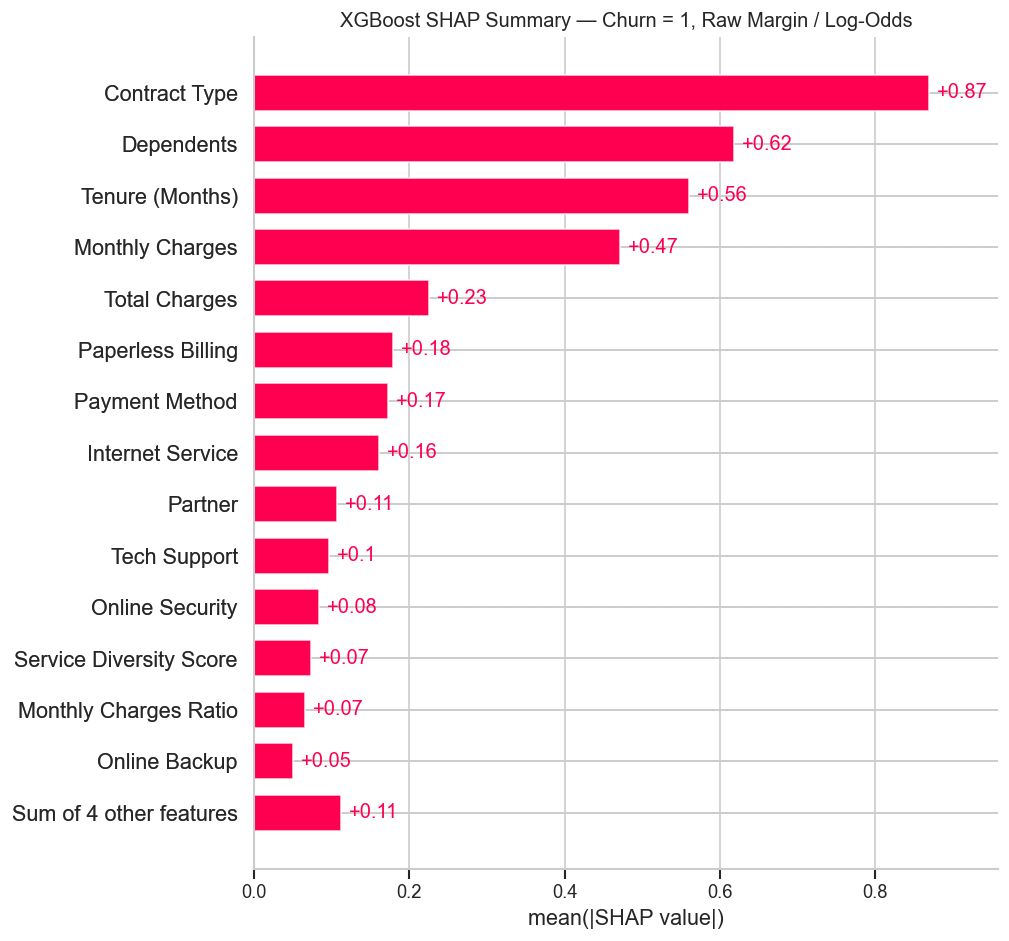

Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_05_xgboost_shap_beeswarm.png


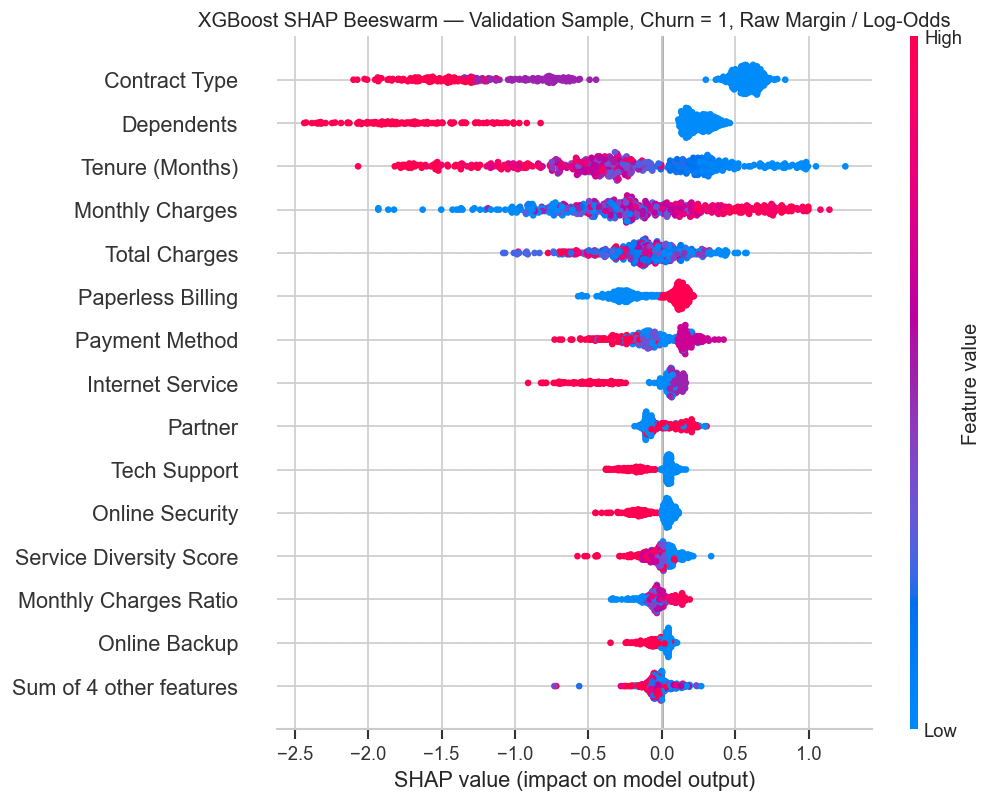

Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_06_xgboost_shap_dependence_top_feature.png


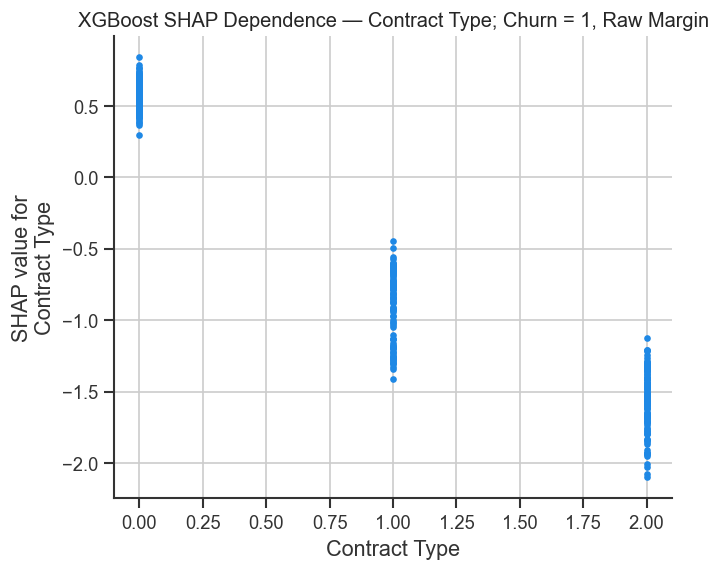

Saved 300-DPI figure: D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\figures\model_interpretation_07_xgboost_shap_waterfall_high_risk_customer.png


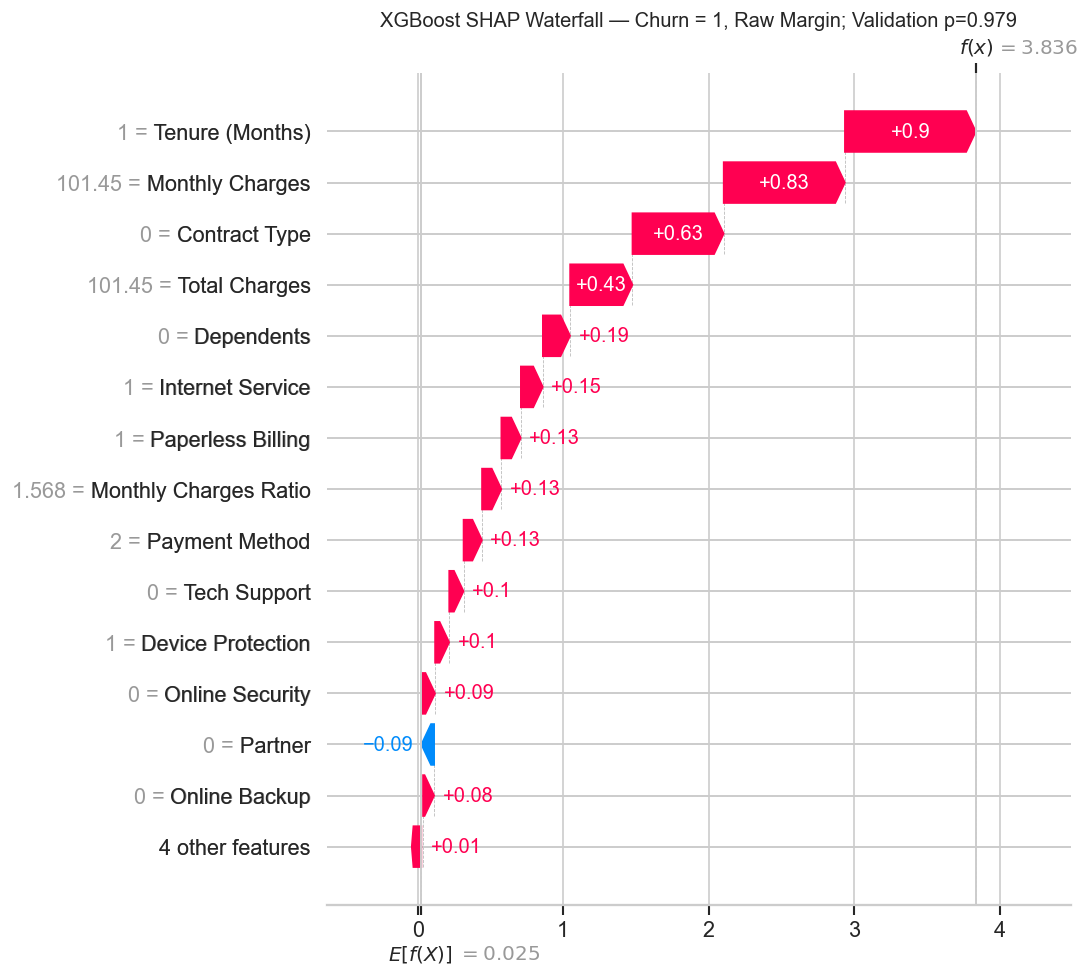

WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/figures/model_interpretation_07_xgboost_shap_waterfall_high_risk_customer.png')

In [24]:
plt.figure(figsize=(9, 7))
shap.plots.bar(shap_explanation_display, max_display=TOP_N_FEATURES, show=False)
plt.title("XGBoost SHAP Summary — Churn = 1, Raw Margin / Log-Odds")
save_figure("model_interpretation_04_xgboost_shap_summary_bar.png", tight=False)

plt.figure(figsize=(10, 8))
shap.plots.beeswarm(shap_explanation_display, max_display=TOP_N_FEATURES, show=False)
plt.title("XGBoost SHAP Beeswarm — Validation Sample, Churn = 1, Raw Margin / Log-Odds")
save_figure("model_interpretation_05_xgboost_shap_beeswarm.png", tight=False)

top_feature_code = shap_importance.loc[0, "Feature_Code"]
top_feature_display = shap_importance.loc[0, "Feature_Display_Name"]
top_feature_index = list(X_train.columns).index(top_feature_code)
plt.figure(figsize=(9, 6))
shap.dependence_plot(top_feature_index, shap_explanation_raw.values, X_shap_display,
                     feature_names=display_feature_names, show=False, interaction_index=None)
plt.title(f"XGBoost SHAP Dependence — {top_feature_display}; Churn = 1, Raw Margin")
save_figure("model_interpretation_06_xgboost_shap_dependence_top_feature.png", tight=False)

plt.figure(figsize=(10, 7))
shap.plots.waterfall(high_risk_explanation_display, max_display=TOP_N_FEATURES, show=False)
plt.title(f"XGBoost SHAP Waterfall — Churn = 1, Raw Margin; Validation p={high_risk_probability:.3f}")
save_figure("model_interpretation_07_xgboost_shap_waterfall_high_risk_customer.png", tight=False)


## 12. Rank overlap and method-separated driver table


In [25]:
method_tables = []
logistic_method = logistic_coefficients_summary.head(10).copy()
logistic_method["Method_Value"] = logistic_method["Abs_Coefficient"]
method_tables.append(logistic_method[["Method", "Feature_Code", "Feature_Display_Name", "Rank", "Driver_Group", "Method_Value", "Value_Unit", "Comparison_Note"]])
for table in [random_forest_top_features, xgboost_top_features, lightgbm_top_features, catboost_top_features]:
    work = table.head(10).copy().rename(columns={"Importance": "Method_Value"})
    method_tables.append(work[["Method", "Feature_Code", "Feature_Display_Name", "Rank", "Driver_Group", "Method_Value", "Value_Unit", "Comparison_Note"]])
shap_method = shap_importance.head(10).copy()
shap_method["Method"] = "XGBoost SHAP mean absolute impact"
shap_method["Method_Value"] = shap_method["Mean_Abs_SHAP"]
shap_method["Value_Unit"] = "mean absolute SHAP on raw margin / log-odds scale"
shap_method["Comparison_Note"] = "Method-specific magnitude; compare ranks, not raw values across methods."
method_tables.append(shap_method[["Method", "Feature_Code", "Feature_Display_Name", "Rank", "Driver_Group", "Method_Value", "Value_Unit", "Comparison_Note"]])

top_business_drivers = pd.concat(method_tables, ignore_index=True)
invalid_tenure_rows = top_business_drivers[
    ((top_business_drivers['Feature_Code'] == 'Tenure') & (top_business_drivers['Feature_Display_Name'] != 'Tenure (Months)'))
    | ((top_business_drivers['Feature_Code'] == 'tenure_group') & (top_business_drivers['Feature_Display_Name'] != 'Tenure Group'))
]
if not invalid_tenure_rows.empty:
    raise ValueError('Tenure and tenure_group were conflated in the driver export.')
if top_business_drivers.duplicated(['Method', 'Feature_Display_Name']).any():
    raise ValueError('Duplicate model-level driver labels detected after display mapping.')
save_table(top_business_drivers, "model_interpretation_top_business_drivers.csv", "Method-separated top business drivers")

rank_overlap = (top_business_drivers.groupby(["Feature_Code", "Feature_Display_Name", "Driver_Group"])
                .agg(Method_Count=("Method", "nunique"), Mean_Rank=("Rank", "mean"), Methods=("Method", lambda values: "; ".join(sorted(set(values)))))
                .reset_index().sort_values(["Method_Count", "Mean_Rank"], ascending=[False, True]).reset_index(drop=True))
rank_overlap["Comparison_Basis"] = "Top-10 rank presence only; raw magnitudes are not compared."
save_table(rank_overlap, "model_interpretation_rank_overlap.csv", "Cross-method top-feature rank overlap")


Method-separated top business drivers: shape=(60, 8); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_top_business_drivers.csv


,Method,Feature_Code,Feature_Display_Name,Rank,Driver_Group,Method_Value,Value_Unit,Comparison_Note
0,Logistic Regression coefficients,TotalCharges,Total Charges,1,Monthly charges / total charges,0.766378,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
1,Logistic Regression coefficients,Contract_24,Contract Type = Two year,2,Contract type,0.683150,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
2,Logistic Regression coefficients,Dependents_Yes,Dependents = Yes,3,Other customer or service profile,0.649922,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
3,Logistic Regression coefficients,InternetService_No,Internet Service = No Internet Service,4,Internet service,0.378273,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
4,Logistic Regression coefficients,Contract_12,Contract Type = One year,5,Contract type,0.336179,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
5,Logistic Regression coefficients,MonthlyCharges,Monthly Charges,6,Monthly charges / total charges,0.334798,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
6,Logistic Regression coefficients,monthly_charges_ratio,Monthly Charges Ratio,7,Monthly charges / total charges,0.334798,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
7,Logistic Regression coefficients,PaperlessBilling_1,Paperless Billing = Yes,8,Paperless billing,0.236857,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
8,Logistic Regression coefficients,Tenure,Tenure (Months),9,Tenure,0.208399,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."
9,Logistic Regression coefficients,InternetService_Fiber optic,Internet Service = Fiber optic,10,Internet service,0.159882,coefficient on the logistic model scale,"Method-specific magnitude; compare ranks, not ..."


Cross-method top-feature rank overlap: shape=(20, 7); saved=D:\FPTU_Study\SU2026\ADY201m\Project_ADY201m_GR01_AI2009_H1\churn_pipeline_v2\reports\data_reports\model_interpretation_rank_overlap.csv


,Feature_Code,Feature_Display_Name,Driver_Group,Method_Count,Mean_Rank,Methods,Comparison_Basis
0,Tenure,Tenure (Months),Tenure,6,4.833333,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
1,MonthlyCharges,Monthly Charges,Monthly charges / total charges,6,5.000000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
2,Contract,Contract Type,Contract type,5,2.000000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
3,TotalCharges,Total Charges,Monthly charges / total charges,5,2.800000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
4,Dependents,Dependents,Other customer or service profile,5,3.400000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
5,monthly_charges_ratio,Monthly Charges Ratio,Monthly charges / total charges,4,5.000000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
6,InternetService,Internet Service,Internet service,4,7.000000,CatBoost FeatureImportance; Random Forest impu...,Top-10 rank presence only; raw magnitudes are ...
7,PaymentMethod,Payment Method,Payment method,4,7.000000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
8,service_diversity,Service Diversity Score,Service diversity,4,9.250000,CatBoost FeatureImportance; LightGBM gain impo...,Top-10 rank presence only; raw magnitudes are ...
9,tenure_group,Tenure Group,Tenure,3,6.666667,CatBoost FeatureImportance; Random Forest impu...,Top-10 rank presence only; raw magnitudes are ...


WindowsPath('D:/FPTU_Study/SU2026/ADY201m/Project_ADY201m_GR01_AI2009_H1/churn_pipeline_v2/reports/data_reports/model_interpretation_rank_overlap.csv')

## 13. Output and source-safety validation


In [26]:
expected_csv = [
    "model_interpretation_logistic_coefficients_summary.csv",
    "model_interpretation_random_forest_top_features.csv",
    "model_interpretation_xgboost_top_features.csv",
    "model_interpretation_lightgbm_top_features.csv",
    "model_interpretation_catboost_top_features.csv",
    "model_interpretation_xgboost_parameter_snapshot.csv",
    "model_interpretation_xgboost_reproducibility_checks.csv",
    "model_interpretation_feature_mapping_used.csv",
    "model_interpretation_xgboost_shap_mean_abs.csv",
    "model_interpretation_top_business_drivers.csv",
    "model_interpretation_rank_overlap.csv",
]
expected_figures = [
    "model_interpretation_01_logistic_top_coefficients.png",
    "model_interpretation_02_random_forest_top_importance.png",
    "model_interpretation_03_xgboost_top_importance.png",
    "model_interpretation_04_xgboost_shap_summary_bar.png",
    "model_interpretation_05_xgboost_shap_beeswarm.png",
    "model_interpretation_06_xgboost_shap_dependence_top_feature.png",
    "model_interpretation_07_xgboost_shap_waterfall_high_risk_customer.png",
    "model_interpretation_08_lightgbm_top_importance.png",
    "model_interpretation_09_catboost_top_importance.png",
]
checks = pd.DataFrame([
    {"File": name, "Exists": (DATA_REPORTS_DIR / name).exists()} for name in expected_csv
] + [{"File": name, "Exists": (FIGURES_DIR / name).exists()} for name in expected_figures])
display(checks)
if not checks["Exists"].all():
    raise FileNotFoundError("Notebook 06 expected outputs are incomplete.")

print("Notebook 06 interpretation-only summary")
print("- Native methods: Logistic coefficients, Random Forest impurity, XGBoost gain, LightGBM gain, CatBoost FeatureImportance.")
print("- Detailed SHAP model: XGBoost only.")
print(f"- SHAP sample: validation n={sample_size}.")
print("- Explained positive class: Churn = 1.")
print("- SHAP output scale: raw model margin / log-odds; not direct probability contributions.")
print("- No model ranking, best-model recommendation, threshold comparison, database access, ingestion, or model artifact write occurs.")


,File,Exists
0,model_interpretation_logistic_coefficients_sum...,True
1,model_interpretation_random_forest_top_feature...,True
2,model_interpretation_xgboost_top_features.csv,True
3,model_interpretation_lightgbm_top_features.csv,True
4,model_interpretation_catboost_top_features.csv,True
5,model_interpretation_xgboost_parameter_snapsho...,True
6,model_interpretation_xgboost_reproducibility_c...,True
7,model_interpretation_feature_mapping_used.csv,True
8,model_interpretation_xgboost_shap_mean_abs.csv,True
9,model_interpretation_top_business_drivers.csv,True


Notebook 06 interpretation-only summary
- Native methods: Logistic coefficients, Random Forest impurity, XGBoost gain, LightGBM gain, CatBoost FeatureImportance.
- Detailed SHAP model: XGBoost only.
- SHAP sample: validation n=500.
- Explained positive class: Churn = 1.
- SHAP output scale: raw model margin / log-odds; not direct probability contributions.
- No model ranking, best-model recommendation, threshold comparison, database access, ingestion, or model artifact write occurs.
